# 05: Reducing LLM Calls: LLM on a Small Subset, a Local Classifier for the Rest

**Why this notebook:** in every run so far, classification was the slowest step, because it makes **one LLM call per text** (~3,000 calls): 10 min with Qwen 2.5, 119 min with Qwen3. The paper's Table 7 shows the same problem for GPT-3.5: API cost grows with every text.

**Idea (contribution #2):**
1. The LLM generates and merges the labels, exactly as before (≈ n/15 calls).
2. The LLM classifies only a **small subset** of the texts (e.g. 10%).
3. A **lightweight local classifier** (logistic regression on E5-large sentence embeddings) is trained on that subset, using the LLM's labels as training labels.
4. The classifier labels **all remaining texts, with zero LLM calls**.

**How we test it without new LLM calls:** notebook 02 saved the LLM's answer for **every** text, and the model runs at temperature 0, so its answer for a text is the same whether we ask for all texts or only a subset. We can therefore simulate "the LLM only saw X% of the texts" by using its saved answers for a sample of X% and hiding the rest. The result is the same as a real run on that subset.

**Two ways to choose the subset:**
- **Random:** a random sample.
- **Representative:** cluster the text embeddings into as many groups as the subset size and take the text closest to each group's center, so the subset covers all kinds of texts. This matches the "small representative subset" in our idea.

**We compare:** subset sizes from 2% to 50%, both selection strategies, averaged over 5 random seeds, against the full method (100% LLM calls).

**Two sources of LLM labels:**
- **C:** the answers from notebook 02 (merge + rescue, A+B+C). The reduced version of this is method **E**.
- **F:** the answers from notebook 07 (with label definitions). Definitions made classification 11× slower (119 min on Massive-I), so here we test whether the LLM can classify only a subset *with definitions* and let the classifier do the rest. This combination is **E+F**.

## 0. Setup
`CONFIGS` lists every run from notebook 02 that we test, with the threshold chosen there. The saved answers are found automatically.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, time, math, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
import evaluate as ev
import given_label_classification as glc

SIZE = "small"
OURS = "A+B+C (merge + rescue)"
# (dataset, model, threshold chosen in notebook 02, source of the LLM answers)
#   "C" = notebook 02 answers (A+B+C);  "F" = notebook 07 answers (with label definitions)
CONFIGS = [("massive_scenario", "qwen2.5:7b", 0.5, "C"),
           ("massive_scenario", "qwen3:8b", 0.6, "C"),
           ("massive_intent", "qwen2.5:7b", 0.4, "C"),
           ("massive_intent", "qwen2.5:7b", 0.4, "F")]
SOURCE_NAME = {"C": "A+B+C", "F": "A+B+C + definitions (F)"}
FRACTIONS = [0.02, 0.05, 0.10, 0.20, 0.30, 0.50]
SEEDS = [0, 1, 2, 3, 4]
NAMES = {"massive_scenario": "Massive-D", "massive_intent": "Massive-I"}

def out_dir(model):
    return "./generated_labels" if model == "qwen2.5:7b" else f"./generated_labels/{model.replace(':', '_')}"

os.makedirs("./results/figures", exist_ok=True)
os.makedirs("./results/tables", exist_ok=True)
results = pd.read_csv("./results/results.csv")
print("Configs:", CONFIGS)

Configs: [('massive_scenario', 'qwen2.5:7b', 0.5, 'C'), ('massive_scenario', 'qwen3:8b', 0.6, 'C'), ('massive_intent', 'qwen2.5:7b', 0.4, 'C'), ('massive_intent', 'qwen2.5:7b', 0.4, 'F')]


## 1. Load the LLM's saved answers
For each config we rebuild the full-method predictions exactly as notebook 02 did: strict matching first, then rescue by meaning (Fix C) for answers that don't match a label. These are the "LLM labels" the classifier learns from.

The rescue uses the same small embedding model (MiniLM) as notebook 02, so the full-method scores match notebook 02.

In [2]:
from sentence_transformers import SentenceTransformer
minilm = SentenceTransformer("all-MiniLM-L6-v2")
def embed_labels(items):
    return minilm.encode([str(x).replace("_", " ") for x in items], normalize_embeddings=True)

def answer_text(raw):
    try:
        obj = glc.parse_json(raw)
        vals = [v for v in obj.values() if isinstance(v, str)]
        return vals[0] if vals else str(raw)
    except Exception:
        return str(raw or "")

def load_llm_predictions(data, model, t, source):
    out = out_dir(model)
    with open(f"{out}/{data}_{SIZE}_improved_labels_t{t}.json", encoding="utf-8") as f:
        labels = json.load(f)
    if source == "F":
        labels = list(dict.fromkeys(labels))      # notebook 07 used the list without duplicates
    raw_file = f"improved_t{t}_raw.jsonl" if source == "C" else f"definitions_t{t}_raw.jsonl"
    raw = {}
    with open(f"{out}/{data}_{SIZE}_{raw_file}", encoding="utf-8") as f:
        for line in f:
            r = json.loads(line); raw[r["i"]] = r["raw"]
    raw = [raw[i] for i in range(len(raw))]
    preds = [glc.answer_process(r, labels) if r else "Unsuccessful" for r in raw]
    failed = [i for i, p in enumerate(preds) if p == "Unsuccessful"]
    if failed:
        E_lab = embed_labels(labels)
        E_ans = embed_labels([answer_text(raw[i]) for i in failed])
        for i, j in zip(failed, (E_ans @ E_lab.T).argmax(axis=1)):
            preds[i] = labels[j]
    return preds, len(labels)

DATA_CACHE = {}
for data, model, t, source in CONFIGS:
    gold = ev.load_data("./dataset/", data, SIZE == "large")
    texts = [g["input"] for g in gold]
    preds, n_labels = load_llm_predictions(data, model, t, source)
    assert len(preds) == len(texts), f"{data}/{model}/{source}: {len(preds)} answers for {len(texts)} texts"
    DATA_CACHE[(data, model, source)] = {"texts": texts, "gold": ev.get_labels(gold), "llm": preds, "n_labels": n_labels}
    print(f"{NAMES[data]} / {model} / {SOURCE_NAME[source]}: {len(texts)} texts, {len(set(preds))} LLM clusters")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Massive-D / qwen2.5:7b / A+B+C: 2974 texts, 36 LLM clusters
Massive-D / qwen3:8b / A+B+C: 2974 texts, 93 LLM clusters
Massive-I / qwen2.5:7b / A+B+C: 2974 texts, 59 LLM clusters
Massive-I / qwen2.5:7b / A+B+C + definitions (F): 2974 texts, 61 LLM clusters


## 2. Text embeddings for the classifier
We use **E5-large**, the stronger embedding model from notebook 03. Its embeddings were saved there, so they are reused here. If a dataset wasn't run in notebook 03, they are computed now (a few minutes on CPU).

**Why a logistic regression on frozen embeddings?** It trains in seconds, runs on any CPU, and needs no GPU. Fine-tuning the whole encoder (e.g. SetFit) could be slightly more accurate but is much slower; we leave it as future work.

In [3]:
EMB = {}
for data in {c[0] for c in CONFIGS}:
    path = f"./results/embeddings/{data}_e5-large-v2.npy"
    if os.path.exists(path):
        EMB[data] = np.load(path)
    else:
        os.makedirs("./results/embeddings", exist_ok=True)
        e5 = SentenceTransformer("intfloat/e5-large-v2")
        texts = next(v["texts"] for k, v in DATA_CACHE.items() if k[0] == data)
        EMB[data] = e5.encode(["query: " + t for t in texts], batch_size=64, normalize_embeddings=True, show_progress_bar=True)
        np.save(path, EMB[data])
    print(data, EMB[data].shape)

massive_intent (2974, 1024)
massive_scenario (2974, 1024)


## 3. Run the experiment
For each config, subset size and seed:
1. pick the subset (random or representative);
2. keep the LLM's labels for the subset;
3. train the classifier on the subset and predict the rest;
4. score the combined labels (subset from the LLM, rest from the classifier) against the true labels.

**LLM calls** = label generation (≈ n/15) + the subset, plus one call per label to write the definitions for source F. With 10%, that's about **17% of the original calls** for these datasets.

In [4]:
def pick_subset(E, m, strategy, seed):
    rng = np.random.default_rng(seed)
    if strategy == "random":
        return rng.choice(len(E), size=m, replace=False)
    # Representative: one text per K-means group, the one closest to the group's center
    km = KMeans(n_clusters=m, n_init=1, random_state=seed).fit(E)
    idx = []
    for c in range(m):
        members = np.where(km.labels_ == c)[0]
        if len(members):
            idx.append(members[np.argmin(((E[members] - km.cluster_centers_[c]) ** 2).sum(1))])
    return np.array(idx)

def score(gold, preds):
    with contextlib.redirect_stdout(io.StringIO()):
        y_true, _ = ev.convert_label_to_ids(gold)
        y_pred, k = ev.convert_label_to_ids(preds)
        s = ev.clustering_score(y_true, y_pred)
    return {m: float(v) for m, v in s.items()}, k

rows = []
t0 = time.time()
for data, model, t, source in CONFIGS:
    c = DATA_CACHE[(data, model, source)]; E = EMB[data]; n = len(c["texts"])
    extra = c["n_labels"] if source == "F" else 0          # definition-writing calls
    llm = np.array(c["llm"], dtype=object)
    full, k_full = score(c["gold"], list(llm))
    rows.append({"dataset": data, "model": model, "source": source, "threshold": t, "strategy": "full LLM", "fraction": 1.0, "seed": 0,
                 **full, "clusters": k_full, "lost_clusters": 0, "llm_calls": math.ceil(n / 15) + extra + n})
    for strategy in ["random", "representative"]:
        for f in FRACTIONS:
            for seed in SEEDS:
                idx = pick_subset(E, max(2, int(f * n)), strategy, seed)
                mask = np.zeros(n, dtype=bool); mask[idx] = True
                combined = llm.copy()
                if len(set(llm[mask])) > 1:
                    clf = LogisticRegression(max_iter=2000, C=10).fit(E[mask], llm[mask])
                    combined[~mask] = clf.predict(E[~mask])
                else:
                    combined[~mask] = llm[mask][0]
                s, k = score(c["gold"], list(combined))
                rows.append({"dataset": data, "model": model, "source": source, "threshold": t, "strategy": strategy, "fraction": f,
                             "seed": seed, **s, "clusters": k, "lost_clusters": len(set(llm)) - len(set(llm[mask])),
                             "llm_calls": math.ceil(n / 15) + extra + int(mask.sum())})
    print(f"{NAMES[data]} / {model} / {SOURCE_NAME[source]} done ({time.time() - t0:.0f} s)")
runs = pd.DataFrame(rows)

Massive-D / qwen2.5:7b / A+B+C done (197 s)


c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklear

Massive-D / qwen3:8b / A+B+C done (376 s)


c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)


Massive-I / qwen2.5:7b / A+B+C done (562 s)


c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
c:\Users\itsfr\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklear

Massive-I / qwen2.5:7b / A+B+C + definitions (F) done (1555 s)


## 4. Results table (mean over 5 seeds)
- **% of LLM calls:** compared with the full method (label generation + classifying every text).
- **ACC / NMI / ARI kept:** the score as a percentage of the full method's score. E.g. "95%" means 5% of the accuracy was lost.
- **Lost clusters:** LLM clusters that never appeared in the subset, so the classifier cannot predict them. This is a risk of small subsets.

In [5]:
summary = (runs.groupby(["dataset", "model", "source", "strategy", "fraction"])
               [["ACC", "NMI", "ARI", "clusters", "lost_clusters", "llm_calls"]].mean().reset_index())
full = summary[summary.strategy == "full LLM"].set_index(["dataset", "model", "source"])
for met in ["ACC", "NMI", "ARI"]:
    summary[f"{met} kept"] = [f"{100 * r[met] / full.loc[(r.dataset, r.model, r.source), met]:.0f}%" for _, r in summary.iterrows()]
summary["% of LLM calls"] = [f"{100 * r.llm_calls / full.loc[(r.dataset, r.model, r.source), 'llm_calls']:.0f}%" for _, r in summary.iterrows()]
summary["Dataset"] = summary.dataset.map(NAMES)
summary["LLM labels"] = summary.source.map(SOURCE_NAME)
show = summary[["Dataset", "model", "LLM labels", "strategy", "fraction", "% of LLM calls", "ACC", "NMI", "ARI",
                "ACC kept", "NMI kept", "ARI kept", "clusters", "lost_clusters"]].copy()
for m in ["ACC", "NMI", "ARI"]:
    show[m] = (100 * show[m]).round(1)
show["clusters"] = show.clusters.round(0).astype(int); show["lost_clusters"] = show.lost_clusters.round(1)
show = show.sort_values(["Dataset", "model", "LLM labels", "strategy", "fraction"])
show.to_csv("./results/tables/cost_reduction.csv", index=False)
pd.set_option("display.max_rows", 200)
show

,Dataset,model,LLM labels,strategy,fraction,% of LLM calls,ACC,NMI,ARI,ACC kept,NMI kept,ARI kept,clusters,lost_clusters
26,Massive-D,qwen2.5:7b,A+B+C,full LLM,1.00,100%,49.4,58.9,38.6,100%,100%,100%,36,0.0
27,Massive-D,qwen2.5:7b,A+B+C,random,0.02,8%,41.1,40.1,22.3,83%,68%,58%,25,11.4
28,Massive-D,qwen2.5:7b,A+B+C,random,0.05,11%,47.9,52.2,30.2,97%,89%,78%,31,5.2
29,Massive-D,qwen2.5:7b,A+B+C,random,0.10,16%,53.5,60.5,39.7,108%,103%,103%,34,2.2
30,Massive-D,qwen2.5:7b,A+B+C,random,0.20,25%,53.7,62.0,41.0,109%,105%,106%,34,2.0
31,Massive-D,qwen2.5:7b,A+B+C,random,0.30,34%,53.6,62.5,41.5,109%,106%,108%,34,1.6
32,Massive-D,qwen2.5:7b,A+B+C,random,0.50,53%,52.4,61.3,40.6,106%,104%,105%,35,0.6
33,Massive-D,qwen2.5:7b,A+B+C,representative,0.02,8%,51.1,51.9,31.9,104%,88%,83%,26,9.6
34,Massive-D,qwen2.5:7b,A+B+C,representative,0.05,11%,55.3,59.5,39.8,112%,101%,103%,31,5.4
35,Massive-D,qwen2.5:7b,A+B+C,representative,0.10,16%,55.2,62.0,41.6,112%,105%,108%,33,3.0


## 5. Accuracy vs LLM calls
Each line shows how the scores change as the LLM classifies a larger share of the texts. The dashed line is the full method (100%). The closer a line gets to it with few calls, the better the trade-off.

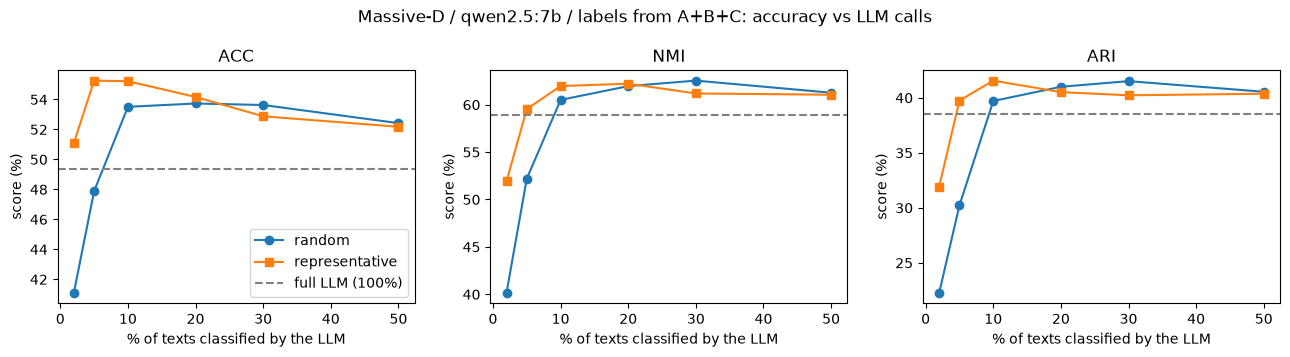

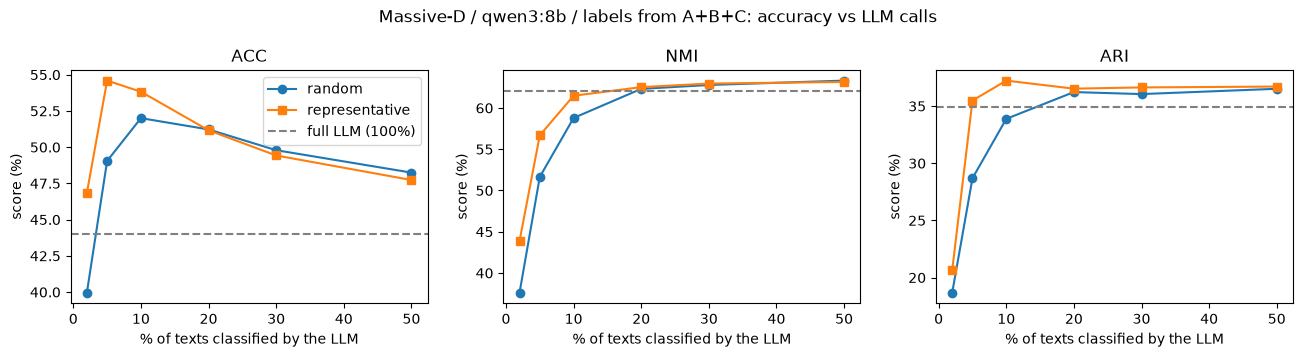

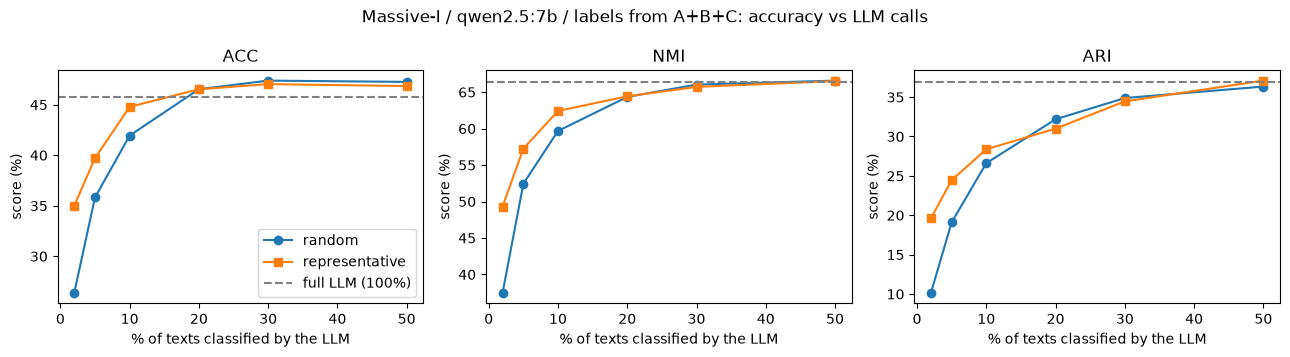

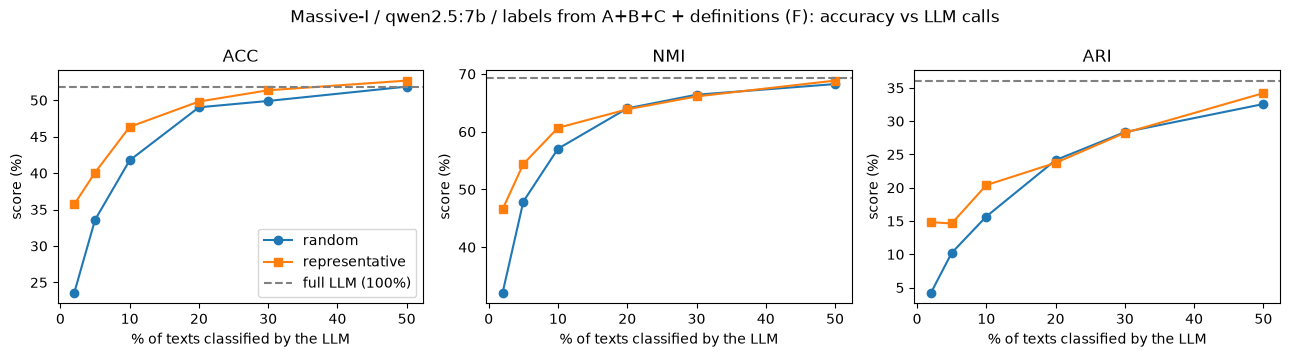

In [6]:
for data, model, t, source in CONFIGS:
    s = summary[(summary.dataset == data) & (summary.model == model) & (summary.source == source)]
    fl = s[s.strategy == "full LLM"].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
    for ax, met in zip(axes, ["ACC", "NMI", "ARI"]):
        for strategy, style in [("random", "o-"), ("representative", "s-")]:
            x = s[s.strategy == strategy]
            ax.plot(100 * x.fraction, 100 * x[met], style, label=strategy)
        ax.axhline(100 * fl[met], ls="--", c="gray", label="full LLM (100%)")
        ax.set_title(met); ax.set_xlabel("% of texts classified by the LLM"); ax.set_ylabel("score (%)")
    axes[0].legend()
    fig.suptitle(f"{NAMES[data]} / {model} / labels from {SOURCE_NAME[source]}: accuracy vs LLM calls")
    plt.tight_layout(); plt.savefig(f"./results/figures/cost_{data}_{model.replace(':', '_')}_{source}.png", dpi=200); plt.show()

## 6. Time saved
Estimated classification time for each subset size, based on the measured time per LLM call in notebook 02 for each model.

In [7]:
# measured classification minutes for all texts (notebook 02 for C, notebook 07 for F)
TIME = {("massive_scenario", "qwen2.5:7b", "C"): 9.5, ("massive_scenario", "qwen3:8b", "C"): 119.0,
        ("massive_intent", "qwen2.5:7b", "C"): 10.6, ("massive_intent", "qwen2.5:7b", "F"): 119.0}
trows = []
for (data, model, source), minutes in TIME.items():
    if (data, model, source) not in DATA_CACHE:
        continue
    for f in FRACTIONS:
        r = summary[(summary.dataset == data) & (summary.model == model) & (summary.source == source) & (summary.strategy == "representative") & (summary.fraction == f)].iloc[0]
        trows.append({"Dataset": NAMES[data], "model": model, "LLM labels": SOURCE_NAME[source], "% texts by LLM": f"{100 * f:.0f}%",
                      "classification time (min)": round(minutes * f, 1), "full method (min)": minutes,
                      "ACC (repr.)": round(100 * r.ACC, 1)})
pd.DataFrame(trows)

,Dataset,model,LLM labels,% texts by LLM,classification time (min),full method (min),ACC (repr.)
0,Massive-D,qwen2.5:7b,A+B+C,2%,0.2,9.5,51.1
1,Massive-D,qwen2.5:7b,A+B+C,5%,0.5,9.5,55.3
2,Massive-D,qwen2.5:7b,A+B+C,10%,1.0,9.5,55.2
3,Massive-D,qwen2.5:7b,A+B+C,20%,1.9,9.5,54.2
4,Massive-D,qwen2.5:7b,A+B+C,30%,2.9,9.5,52.9
5,Massive-D,qwen2.5:7b,A+B+C,50%,4.8,9.5,52.2
6,Massive-D,qwen3:8b,A+B+C,2%,2.4,119.0,46.8
7,Massive-D,qwen3:8b,A+B+C,5%,6.0,119.0,54.6
8,Massive-D,qwen3:8b,A+B+C,10%,11.9,119.0,53.8
9,Massive-D,qwen3:8b,A+B+C,20%,23.8,119.0,51.2


## 7. Save to results.csv
We save the **representative-subset** results as reported variants, next to the full methods, so notebook 04 can include them:
- **E** = A+B+C labels, LLM on 10%;
- **E+F** = labels with definitions, LLM on 10% and on 20% (fine-grained intents needed 20% in the E experiment).

In [9]:
SAVE = [("C", 0.10, "E (A+B+C, LLM on 10% + classifier)"),
        ("F", 0.10, "E+F (definitions, LLM on 10% + classifier)"),
        ("F", 0.50, "E+F (definitions, LLM on 50% + classifier)")]
res = pd.read_csv("./results/results.csv")
new = []
for data, model, t, source in CONFIGS:
    for src, frac, method in SAVE:
        if src != source:
            continue
        r = summary[(summary.dataset == data) & (summary.model == model) & (summary.source == source)
                    & (summary.strategy == "representative") & (summary.fraction == frac)].iloc[0]
        c = DATA_CACHE[(data, model, source)]
        new.append({"method": method, "dataset": data, "model": model, "n_texts": len(c["texts"]),
                    "true_clusters": len(set(c["gold"])), "predicted_clusters": int(round(r.clusters)),
                    "ACC": round(r.ACC, 4), "ARI": round(r.ARI, 4), "NMI": round(r.NMI, 4), "unsuccessful": 0,
                    "llm_calls": int(round(r.llm_calls)), "time_min": round(TIME.get((data, model, source), np.nan) * frac, 1),
                    "threshold": t, "date": time.strftime("%Y-%m-%d %H:%M")})
new = pd.DataFrame(new)
key = lambda df: df.method + "|" + df.dataset + "|" + df.model
res = res[~key(res).isin(key(new))]
res = pd.concat([res, new], ignore_index=True)
res.to_csv("./results/results.csv", index=False)
new

,method,dataset,model,n_texts,true_clusters,predicted_clusters,ACC,ARI,NMI,unsuccessful,llm_calls,time_min,threshold,date
0,"E (A+B+C, LLM on 10% + classifier)",massive_scenario,qwen2.5:7b,2974,18,33,0.5522,0.4156,0.6197,0,496,1.0,0.5,2026-11-13 18:06
1,"E (A+B+C, LLM on 10% + classifier)",massive_scenario,qwen3:8b,2974,18,59,0.5383,0.3723,0.6149,0,496,11.9,0.6,2026-11-13 18:06
2,"E (A+B+C, LLM on 10% + classifier)",massive_intent,qwen2.5:7b,2974,59,49,0.4479,0.2838,0.6242,0,496,1.1,0.4,2026-11-13 18:06
3,"E+F (definitions, LLM on 10% + classifier)",massive_intent,qwen2.5:7b,2974,59,51,0.4634,0.2040,0.6066,0,557,11.9,0.4,2026-11-13 18:06
4,"E+F (definitions, LLM on 50% + classifier)",massive_intent,qwen2.5:7b,2974,59,60,0.5269,0.3422,0.6884,0,1747,59.5,0.4,2026-11-13 18:06


**Note:** the combined result can be slightly *higher* than the full method. The classifier learns the general pattern from the LLM's labels and can smooth out some of the LLM's individual mistakes. If this happens, report it, but don't overclaim it: it depends on the dataset.

## Findings (fill in after running)
1. **How much accuracy is kept with 10% of the texts classified by the LLM?** (ACC / NMI / ARI kept, per dataset.)
2. **Random vs representative:** does choosing a representative subset keep more accuracy, especially at small sizes (2–5%)?
3. **Lost clusters:** how many LLM clusters disappear at small subsets, and which dataset suffers most (Massive-I has more, smaller clusters)?
4. **Time:** how much classification time is saved (e.g. Qwen3 on Massive-D: 119 min → about 12 min at 10%)?
5. **Sweet spot:** the smallest subset size that keeps about 95% of the full method's ACC.
6. **E+F (definitions):** with definitions, does a 10–20% subset keep F's gains on Massive-I (ACC 51.8) while cutting its 119-minute classification to about 12–24 minutes?